<a href="https://colab.research.google.com/github/Muhammad-Mehdi-0/ML-Labs/blob/main/Lab2_Data_Cleaning_EDA_Template_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2: From Raw Data to ML-Ready Data
## Data Cleaning & Exploratory Data Analysis — Telco Customer Churn

**Name:** _Muhammad Mehdi Mangi_

**Roll Number:** _023-24-0028_

**GitHub Repository:** _(link, added before submission)_

**Duration:** 3 Hours (independent, hands-on)

> This notebook is a **template**, not a tutorial. You already know Python, NumPy, Pandas, and Matplotlib from previous labs. Each section below states the objective and the questions you must answer — **you decide** which functions/plots are appropriate. Do not just run code without interpreting it: every visualization needs a written observation, and every cleaning decision needs a written justification.
>
> Fill in the empty code cells and the *Answer:* / *Observation:* placeholders directly in this notebook. Do not delete the Markdown headings — they are used for grading.

---

## Setup

Import the libraries you'll need and load the dataset. Use the Telco Customer Churn CSV provided for this lab.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

from google.colab import files
uploaded = files.upload()   # choose the Telco CSV when the dialog opens

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


---

## Part 1 — The Business Problem

A telecommunications company is losing customers to competitors — this is called **customer churn**. The company wants to understand which customers are likely to leave, so it can intervene early. Before any model can be built, the raw data must be understood, audited for quality issues, and explored.

**Tasks**
1. In 2–3 sentences, state the business problem in your own words, and propose what the target variable likely is.
2. List 5 columns you expect to be useful predictors of churn, and 2 columns you expect to be useless as predictors — justify each choice in one line.
3. Write down 2 questions you personally want this data to answer about customers who churn.

The telecom company loses customers to competitors, and keeping a customer costs far less than winning a new one. We want to identify who is likely to leave so the company can step in early. The target variable is Churn (Yes/No).
Task 2:

Likely useful: Contract (month-to-month customers can leave freely), tenure (new customers churn more), MonthlyCharges (high bills push people away), InternetService (fiber users often pay more), PaymentMethod (electronic check is often linked to higher churn).
Likely useless: customerID (a random identifier) and gender (no business reason it should drive churn).

Task 3: Pick two questions, for example: “Do customers with short tenure churn much more?” and “Does contract type change the churn rate?”

---

## Part 2 — Exploring the Dataset Structure

Before cleaning or analyzing anything, get an accurate picture of the dataset's shape and contents. Running a command is not the same as understanding its output — you must interpret what you see.

*Concepts/functions you may find useful:* `df.shape`, `df.columns`, `df.dtypes`, `df.info()`, `df.head()`, `df.sample(n)`, `df[col].unique()`, `df[col].nunique()`, `df.describe(include='all')`

**Tasks**
4. How many customers and how many features are in this dataset? List the numerical features and the categorical features separately.
5. Identify any column(s) that are simply identifiers rather than predictive features, and any column(s) whose data type looks wrong for what it represents.
6. Pick 3 categorical columns and report their unique values — do any contain unexpected or inconsistent categories?

In [2]:
# Task 4
print("Rows, columns:", df.shape)
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Numerical:", num_cols)
print("Categorical:", cat_cols)


Rows, columns: (7043, 21)
Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


In [3]:
# Task 6 - unique values of 3 categorical columns
for c in ["MultipleLines", "InternetService", "Contract"]:
    print(c, "->", df[c].unique())


MultipleLines -> ['No phone service' 'No' 'Yes']
InternetService -> ['DSL' 'Fiber optic' 'No']
Contract -> ['Month-to-month' 'One year' 'Two year']


**Observations (Part 2):**
_(summarize what you found — numerical features, categorical features, suspicious columns, etc.)_

---

## Part 3 — Investigating Data Quality

A dataset can look clean at a glance and still hide serious problems. You must actively search for missing values, duplicates, and suspicious values rather than assume there are none.

*Concepts/functions you may find useful:* `df.isnull().sum()`, `df.isnull().mean()*100`, `df.duplicated().sum()`, `df['id_col'].duplicated().sum()`, `df[col].value_counts()`

**Tasks**
7. Report missing values as both a count and a percentage per column. Which missing-value problems do you think require action, and which don't? Justify your reasoning.
8. Check for duplicate rows and duplicate customer IDs separately — are they the same issue or different issues?
9. Find at least one column with a suspicious, invalid, or inconsistently formatted value, and describe how you found it.

In [4]:
# Task 7 - missing values
missing = pd.DataFrame({"count": df.isnull().sum(),
                        "percent": (df.isnull().mean()*100).round(2)})
print(missing)


                  count  percent
customerID            0      0.0
gender                0      0.0
SeniorCitizen         0      0.0
Partner               0      0.0
Dependents            0      0.0
tenure                0      0.0
PhoneService          0      0.0
MultipleLines         0      0.0
InternetService       0      0.0
OnlineSecurity        0      0.0
OnlineBackup          0      0.0
DeviceProtection      0      0.0
TechSupport           0      0.0
StreamingTV           0      0.0
StreamingMovies       0      0.0
Contract              0      0.0
PaperlessBilling      0      0.0
PaymentMethod         0      0.0
MonthlyCharges        0      0.0
TotalCharges          0      0.0
Churn                 0      0.0


In [6]:
# Task 8 - duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customerIDs: 0


In [7]:
# Task 9 - the hidden problem
print(df["TotalCharges"].dtype)
bad = df[pd.to_numeric(df["TotalCharges"], errors="coerce").isnull()]
print(len(bad))
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]


object
11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Answer 7 (which missing-value problems need action, and why):**
isnull() shows 0 missing everywhere, which looks clean. This is the trap, and Task 9 reveals it. Write that the apparent absence of missing values is misleading.

**Answer 8 (duplicate rows vs duplicate IDs — same issue or different?):**
Task 8: There should be 0 duplicate rows and 0 duplicate IDs. They are different checks. A duplicate row is a fully repeated record. A duplicate ID would mean one customer appears twice with different details.


**Answer 9 (suspicious value found and how):**
TotalCharges has 11 rows holding a blank space " " instead of a number, which is why the column is text. All 11 rows have tenure = 0, so they are brand-new customers who haven’t been billed yet. Say you found this by trying pd.to_numeric(..., errors="coerce") and checking which rows became NaN.

---

## Part 4 — Data Cleaning Decisions

Cleaning is a series of justified decisions, not a fixed recipe. For every issue you fix, you must be able to explain why you chose that method over an alternative.

*Concepts/functions you may find useful:* `pd.to_numeric(s, errors='coerce')`, `df.fillna(value)`, `df.dropna()`, `df.drop_duplicates()`, `df[col].str.strip()`, `df.astype(dtype)`

**Tasks**
10. For every data-quality issue you found in Part 3, record: Problem → Decision → Method Used → Reason.
11. Apply your cleaning decisions to produce an intermediate cleaned dataframe, and confirm (with code output) that each issue is actually resolved.

Problem	Decision  	Method  Used	Reason
TotalCharges stored as text (object)	Convert to numeric	pd.to_numeric(errors="coerce")	A charge amount must be numeric for modeling.
11 rows with a blank " " in TotalCharges (all tenure = 0)	Fill with 0	fillna(0)	These customers just joined and haven’t been billed yet, so 0 is the true value. Dropping would lose real customers, and the median would invent a charge they never paid.
isnull() showed 0 missing, but blanks were hidden	No separate action	Fixed by the step above	Blanks were whitespace strings, not NaN.
customerID	Remove at the end (Part 11)	drop(columns=...)	It’s a unique identifier with no predictive value.
MultipleLines / OnlineSecurity etc. contain “No phone service” / “No internet service”	Keep as is	None	It’s a valid category that simply repeats another column. It’s harmless for tree models and is handled by encoding.
Duplicate rows / IDs	None needed	None	Both counts were 0.

In [8]:
df_clean = df.copy()

# strip stray whitespace in all text columns
for c in df_clean.select_dtypes(include="object").columns:
    df_clean[c] = df_clean[c].str.strip()

# fix TotalCharges
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
print("NaN before fill:", df_clean["TotalCharges"].isnull().sum())
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

# verify
print("NaN after fill:", df_clean["TotalCharges"].isnull().sum())
print("dtype:", df_clean["TotalCharges"].dtype)
print("Total missing:", df_clean.isnull().sum().sum())
print("Duplicates:", df_clean.duplicated().sum())


NaN before fill: 11
NaN after fill: 0
dtype: float64
Total missing: 0
Duplicates: 0


In [ ]:
# Task 11 (continued) — confirm each issue is resolved (e.g. re-check isnull().sum(), duplicated().sum(), dtypes)


---

## Part 5 — Univariate EDA

Look at individual variables in isolation before looking at relationships. Every chart must be followed by a written interpretation — a graph with no explanation earns no credit.

*Concepts/functions you may find useful:* `df[col].plot(kind='hist')` / `plt.hist()`, `df.boxplot(column=col)`, `df[col].value_counts().plot(kind='bar')`

**Tasks**
12. Visualize the distribution of at least 2 numerical features and 2 categorical features. For each chart, write 1–2 sentences on what you learned.
13. Do any numerical features show outliers or a skewed distribution? What might explain this?

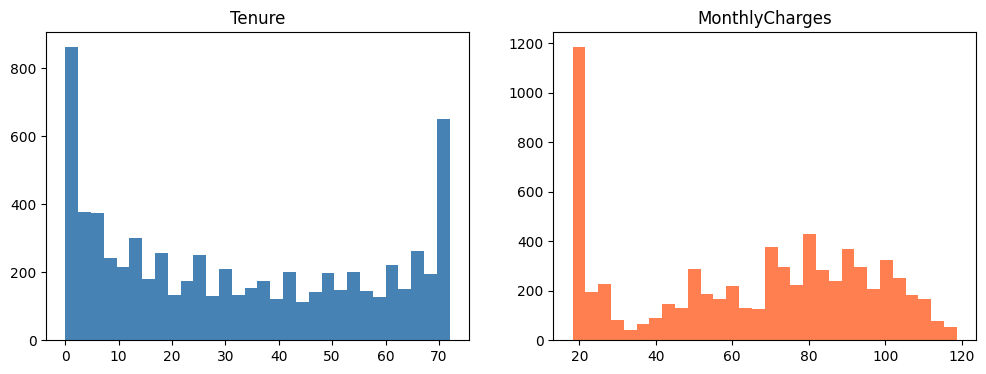

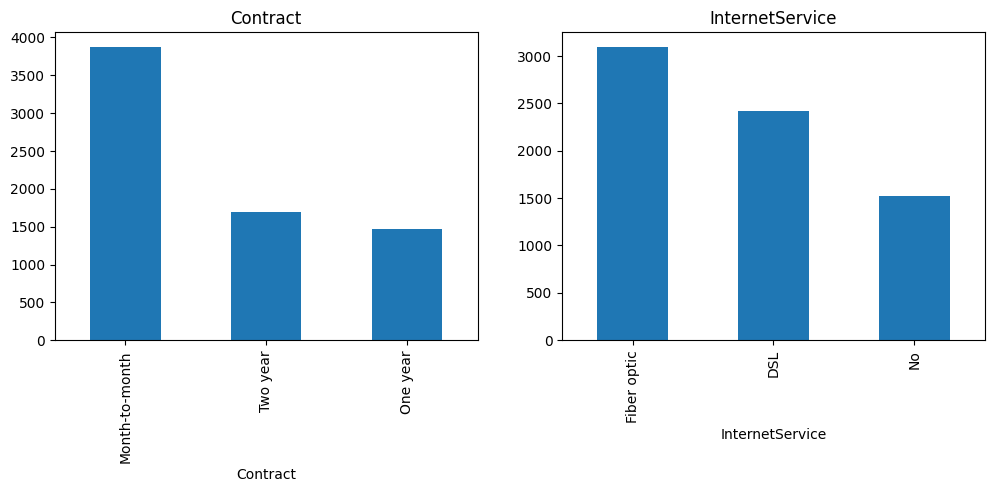

In [9]:
# Task 12 - numerical
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df_clean["tenure"], bins=30, color="steelblue"); ax[0].set_title("Tenure")
ax[1].hist(df_clean["MonthlyCharges"], bins=30, color="coral"); ax[1].set_title("MonthlyCharges")
plt.show()

# Task 12 - categorical
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df_clean["Contract"].value_counts().plot(kind="bar", ax=ax[0], title="Contract")
df_clean["InternetService"].value_counts().plot(kind="bar", ax=ax[1], title="InternetService")
plt.show()


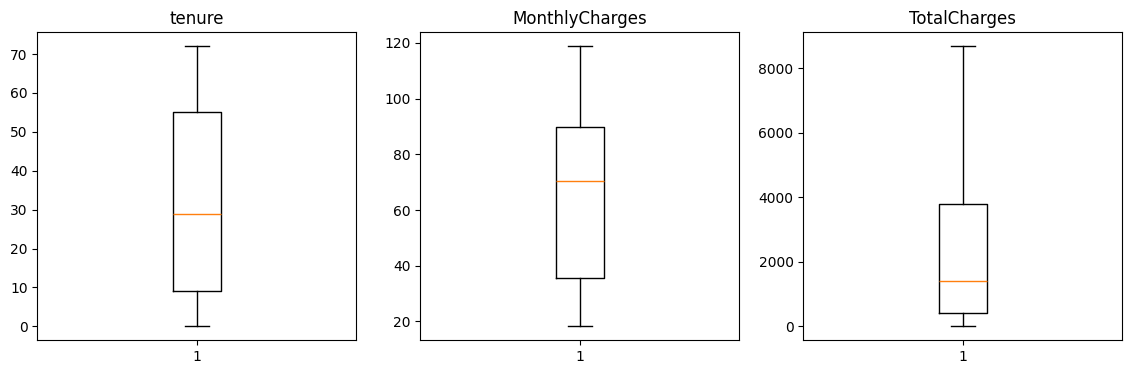

tenure            0.239540
MonthlyCharges   -0.220524
TotalCharges      0.963235
dtype: float64


In [11]:
# Task 13 - outliers / skew
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, ["tenure", "MonthlyCharges", "TotalCharges"]):
    a.boxplot(df_clean[c]); a.set_title(c)
plt.show()
print(df_clean[["tenure", "MonthlyCharges", "TotalCharges"]].skew())


## Part 6 — Target Variable Analysis

The `Churn` column is what you will eventually predict. Before Lab 3, you need to understand its distribution — this has direct consequences for how a model should later be trained and evaluated.

*Concepts/functions you may find useful:* `df['Churn'].value_counts()`, `df['Churn'].value_counts(normalize=True)`

**Tasks**
14. Report the number and percentage of churned vs. non-churned customers. Is the target balanced or imbalanced?
15. In 2–3 sentences, explain why class imbalance might matter when a classification model is trained later — do not describe how to fix it, just why it matters.

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


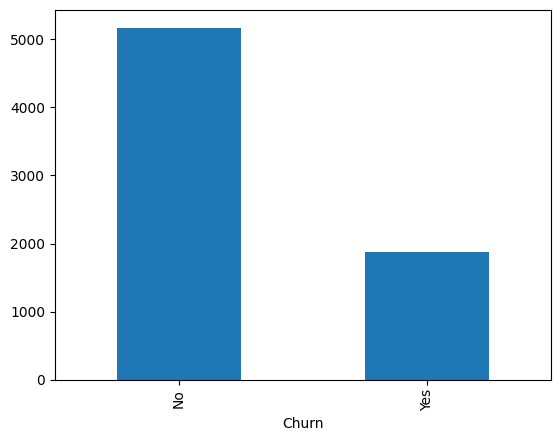

In [12]:
# Task 14
print(df_clean["Churn"].value_counts())
print((df_clean["Churn"].value_counts(normalize=True)*100).round(2))
df_clean["Churn"].value_counts().plot(kind="bar")
plt.show()

## Part 7 — Bivariate Analysis: Features vs. Churn

Now connect individual features to the target. You choose the appropriate visualization or summary for each feature type — a categorical feature is not explored the same way as a numerical one.

*Concepts/functions you may find useful:* `pd.crosstab(df[col], df['Churn'], normalize='index')`, `df.groupby(col)['Churn']...`, `sns.boxplot(x='Churn', y=col, data=df)`

**Tasks**
16. Investigate at least 2 categorical features (e.g. Contract, InternetService, PaymentMethod) against Churn. For each, record: Observation / Evidence / Possible Explanation.
17. Investigate at least 2 numerical features (e.g. tenure, MonthlyCharges) against Churn using the same Observation / Evidence / Possible Explanation format.


--- Contract ---
Churn             No   Yes
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8

--- InternetService ---
Churn              No   Yes
InternetService            
DSL              81.0  19.0
Fiber optic      58.1  41.9
No               92.6   7.4

--- PaymentMethod ---
Churn                        No   Yes
PaymentMethod                        
Bank transfer (automatic)  83.3  16.7
Credit card (automatic)    84.8  15.2
Electronic check           54.7  45.3
Mailed check               80.9  19.1


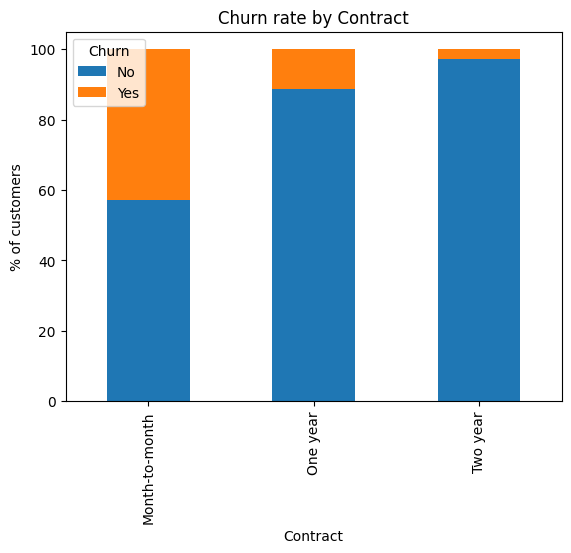

In [13]:
# Task 16 - categorical vs Churn (churn rate per category, in %)
for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(f"\n--- {col} ---")
    print((pd.crosstab(df_clean[col], df_clean["Churn"], normalize="index")*100).round(1))

# plot one of them
(pd.crosstab(df_clean["Contract"], df_clean["Churn"], normalize="index")*100).plot(kind="bar", stacked=True)
plt.ylabel("% of customers"); plt.title("Churn rate by Contract"); plt.show()


       tenure  MonthlyCharges
Churn                        
No       37.6            61.3
Yes      18.0            74.4


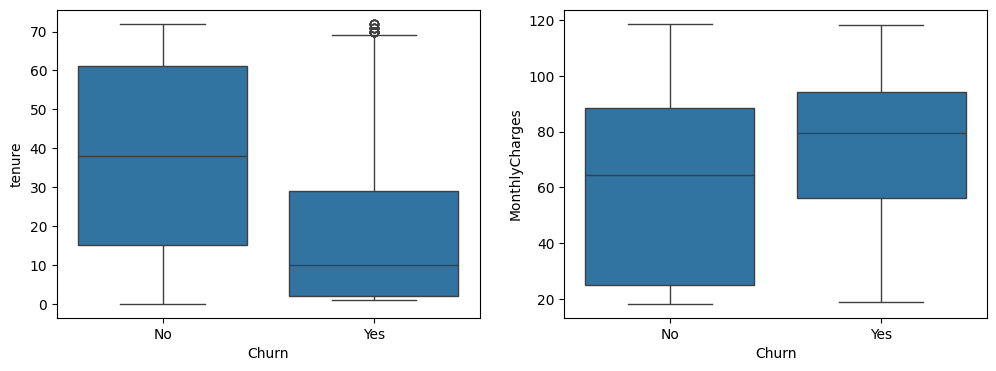

In [14]:
# Task 17 - numerical vs Churn
print(df_clean.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="Churn", y="tenure", data=df_clean, ax=ax[0])
sns.boxplot(x="Churn", y="MonthlyCharges", data=df_clean, ax=ax[1])
plt.show()


---

## Part 8 — Correlation & Feature Relationships

Numerical features can be related to each other, not just to the target. Strongly correlated features can cause redundancy problems later, so it's worth knowing about them now.

*Concepts/functions you may find useful:* `df.corr(numeric_only=True)`, `sns.heatmap(corr_matrix, annot=True)`

**Tasks**
18. Compute and visualize the correlation matrix of the numerical features. Which pairs appear most correlated?
19. Does correlation imply causation here? Could any highly correlated features cause problems for a future model? Answer in 2–3 sentences.

In [ ]:
# Task 18 — correlation matrix and heatmap


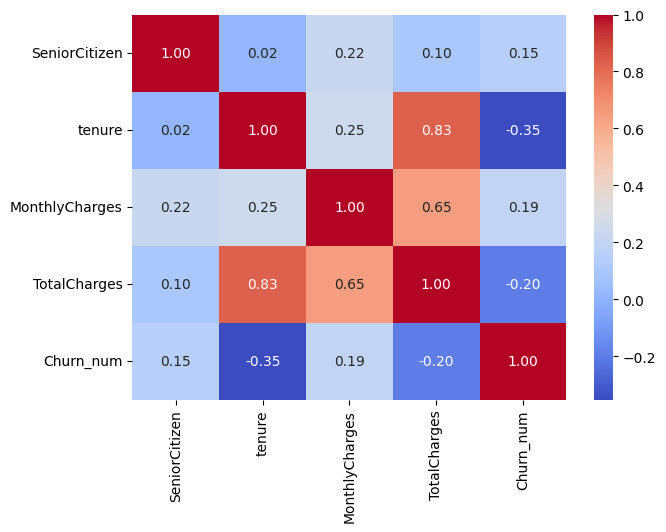

In [15]:
# Task 18 - need a numeric view of Churn for correlation
corr_df = df_clean.copy()
corr_df["Churn_num"] = (corr_df["Churn"] == "Yes").astype(int)
num_for_corr = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges", "Churn_num"]
corr = corr_df[num_for_corr].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

Correlation does not imply causation. TotalCharges is largely tenure × MonthlyCharges, so it correlates with both by construction, not because one causes the other. In a model this redundancy (multicollinearity) can make coefficients unstable, especially in logistic regression, and it adds little new information.

## Part 9 — Data Leakage Awareness

In Lab 3 you will train a classifier. Before that, you must check whether any column contains information that would not realistically be available at the moment of prediction — using such a column would make a model look artificially accurate.

**Tasks**
20. Inspect the columns for anything that looks like it could only be known after a customer has already churned, or that is purely an identifier. List any suspects and explain your reasoning.
21. In 2–3 sentences, explain what would go wrong if such a column were left in the model's input features.

**Answer 20 (suspect columns and reasoning):**
customerID is a pure identifier, so it must be removed. If it were kept, a model could memorize rows instead of learning patterns.
TotalCharges is a mild suspect. It’s derived from tenure and MonthlyCharges, so it’s redundant. It’s not true leakage, because it’s known before the customer churns.
Make it clear nothing here records an outcome that is only known after churning, such as a cancellation reason or churn date.

**Answer 21 (what would go wrong):**
If a column contained post-churn information, the model would use it as a shortcut and score high in testing. It would then fail in real use, because that information wouldn’t exist at prediction time.

---

## Part 10 — ML-Readiness Checklist

Summarize every column's fate in a single table. This is the bridge between EDA and modeling — Lab 3 will use this table directly.

**Task**
22. Complete the ML-readiness table for **every** column in the dataset.

Column	Type	Role	Action	Reason
customerID	Identifier	None	Remove	Unique ID, no predictive value
gender	Categorical	Feature	Keep	Little expected effect, but harmless; encode
SeniorCitizen	Binary (0/1)	Feature	Keep	Already numeric
Partner	Categorical	Feature	Keep	Encode
Dependents	Categorical	Feature	Keep	Encode
tenure	Numerical	Feature	Keep	Strong churn signal
PhoneService	Categorical	Feature	Keep	Encode
MultipleLines	Categorical	Feature	Keep	Encode (“No phone service” is a valid level)
InternetService	Categorical	Feature	Keep	Strong signal; encode
OnlineSecurity	Categorical	Feature	Keep	Encode
OnlineBackup	Categorical	Feature	Keep	Encode
DeviceProtection	Categorical	Feature	Keep	Encode
TechSupport	Categorical	Feature	Keep	Encode
StreamingTV	Categorical	Feature	Keep	Encode
StreamingMovies	Categorical	Feature	Keep	Encode
Contract	Categorical	Feature	Keep	Strongest categorical signal; encode
PaperlessBilling	Categorical	Feature	Keep	Encode
PaymentMethod	Categorical	Feature	Keep	Encode
MonthlyCharges	Numerical	Feature	Keep	Signal; scale later for LR/KNN
TotalCharges	Numerical	Feature	Keep	Fixed dtype; correlated with tenure
Churn	Categorical	Target	Keep	Encode as 0/1

_(Add one row per remaining column — copy the pattern above.)_

---

## Part 11 — Building the Clean Dataset

Bring together every cleaning decision into one final dataframe, `clean_df`, that Lab 3 can load directly.

> Do **not** split into train/test, encode categorical variables, or train any model — that happens in Lab 3.

**Tasks**
23. Produce `clean_df` with correct data types, missing values handled, duplicates handled, and irrelevant identifier columns removed where justified. Save it (e.g. `clean_churn.csv`) alongside your notebook.
24. Print `df.info()` (or equivalent) for `clean_df` as final proof that every issue identified earlier has been resolved.

In [16]:
# Task 23
clean_df = df_clean.copy()

# make sure types are right
clean_df["TotalCharges"] = clean_df["TotalCharges"].astype(float)
clean_df["SeniorCitizen"] = clean_df["SeniorCitizen"].astype(int)

clean_df.to_csv("clean_churn.csv", index=False)
print("Saved:", clean_df.shape)

Saved: (7043, 21)


In [17]:
# Task 24 - proof
clean_df.info()
print("Missing values:", clean_df.isnull().sum().sum())
print("Duplicates:", clean_df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


---

---

---